


###Predicting the Probability of Passing or Failing a Course



## 1. Dataset Source and Loading — Daniel

The CSV used was gotten from Mendeley Data: https://data.mendeley.com/datasets/vzfyk22fhn/4

The file is called Student Performance Dataset. This dataset contains student performance records from an Artificial Intelligence (AI) course conducted staff at Universiti Teknologi Malaysia (UTM). The data includes various academic performance metrics of students enrolled in the course.


It contains students’ assessment scores and final performance categories, which we’re using to define pass/fail. The original dataset was published on the 27 February, 2025 while the updated dataset being used was published on the 17 Dec 2025.

We decided to use this dataset because it is suitable for:
- Educational data mining
- Machine learning applications
- Predictive analytics in AI education
- AI-driven analysis of student performance
- Predicting academic success


Each row represents a distinct student in the Artificial Intelligence (AI) course

The colomns are as follows:
- "Student id"- Used to identify each distinct student.
- "Quiz"- quiz scores for each student (graded over 10 marks).
- "Midterm"- Midterm scores for each student (graded over 15 marks).
- "Assignment_1"- First assignment scores for each student (graded over 5 marks).
- "Assignment_2"- Second assignment scores for each student (graded over 5 marks).
- "Assignment_3"- Third assignment scores for each student (graded over 5 marks).
- "Project"- Project scores for each student (graded over 10 marks).
- "Presentation"- Presentation scores for each student (graded over 10 marks).
- "Final_Exam_Marks"- Final examination scores for each student (graded over 40 marks).
- "Total"- Sum of all previous assesments (100 marks).
- "Grade"- (40-44)"D+", (45-49)"C-", (50-54)"C", (55-59)"C+", (60-64)"B-", (65-69)"B", (70-74)"B+", (75-79)"A-", (80-89)"A", (90-100)"A+".
- "Categories"- (D+)"Fail", (C-,C,C+,B-)"Pass", (B,B+,A-)"Distinction", (A)"Excellent", (A+)"Exceptional".



In [43]:
import pandas as pd

In [44]:
# Loading the dataset from GitHub
df = pd.read_csv(
    "https://raw.githubusercontent.com/emajebiCOS101/student-performance-analysis/main/Student%20Performance%20Dataset%202024.csv"
)

In [45]:
df.head()

,Student Id,Quiz,Midterm,Assignment_1,Assignment_2,Assignment_3,Project,Presentation,Final_Exam_Marks,Total,Grade,Categories
0,1,2.34,6.78,4.56,3.24,4.56,5.67,7.89,24.0,59.04,C+,Pass
1,2,8.17,12.43,2.87,1.87,2.89,2.34,2.34,29.0,61.91,B-,Pass
2,3,5.92,3.21,0.45,4.56,0.76,8.90,5.67,30.0,59.47,C+,Pass
3,4,1.45,9.87,3.12,2.34,3.01,1.23,1.23,33.0,55.25,C+,Pass
4,5,9.78,5.34,0.98,0.98,1.98,9.45,9.01,31.0,68.52,B,Distinction


## 2. Exploratory Data Analysis — Dara

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

In [47]:
print(df.shape)
print(df.info())
print(df.isnull().sum())

(560, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 560 entries, 0 to 559
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Student Id        560 non-null    int64  
 1   Quiz              560 non-null    float64
 2   Midterm           560 non-null    float64
 3   Assignment_1      560 non-null    float64
 4   Assignment_2      560 non-null    float64
 5   Assignment_3      560 non-null    float64
 6   Project           560 non-null    float64
 7   Presentation      560 non-null    float64
 8   Final_Exam_Marks  560 non-null    float64
 9   Total             560 non-null    float64
 10  Grade             560 non-null    object 
 11  Categories        560 non-null    object 
dtypes: float64(9), int64(1), object(2)
memory usage: 52.6+ KB
None
Student Id          0
Quiz                0
Midterm             0
Assignment_1        0
Assignment_2        0
Assignment_3        0
Project             0
Prese

In [48]:
print(df.describe())

       Student Id        Quiz     Midterm  Assignment_1  Assignment_2  \
count  560.000000  560.000000  560.000000    560.000000    560.000000   
mean   280.500000    6.481375    8.545743      3.492179      3.674073   
std    161.802349    2.127193    3.740173      0.912075      0.907100   
min      1.000000    0.000000    0.120000      0.090000      0.210000   
25%    140.750000    5.120000    5.450000      2.980000      3.230000   
50%    280.500000    6.560000    8.065000      3.560000      3.980000   
75%    420.250000    8.230000   12.230000      4.230000      4.232500   
max    560.000000    9.980000   15.000000      4.980000      4.980000   

       Assignment_3     Project  Presentation  Final_Exam_Marks       Total  
count    560.000000  560.000000    560.000000        560.000000  560.000000  
mean       3.505732    7.034429      7.294018         31.174464   71.201276  
std        0.876958    1.913305      1.818343          8.170194   12.394518  
min        0.120000    0.21000

In [49]:
print(df["Categories"].value_counts())

Categories
Distinction    301
Pass            92
Excellent       70
Exceptional     56
Fail            41
Name: count, dtype: int64


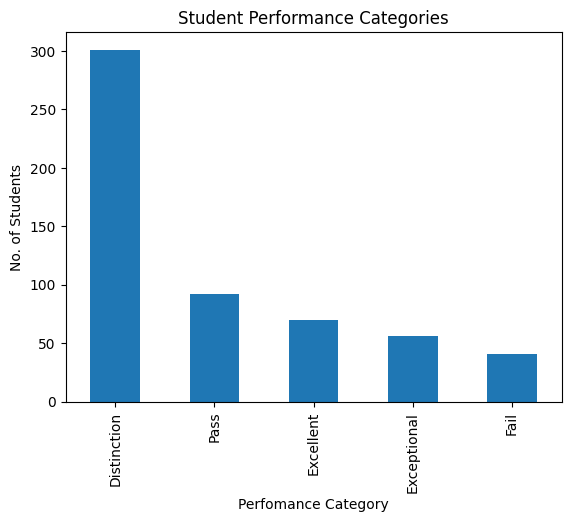

In [50]:
df['Categories'].value_counts().plot(kind='bar')
plt.xlabel('Perfomance Category')
plt.ylabel('No. of Students')
plt.title('Student Performance Categories')
plt.show()

Quiz                 6.481375
Midterm              8.545743
Assignment_1         3.492179
Assignment_2         3.674073
Assignment_3         3.505732
Project              7.034429
Presentation         7.294018
Final_Exam_Marks    31.174464
dtype: float64


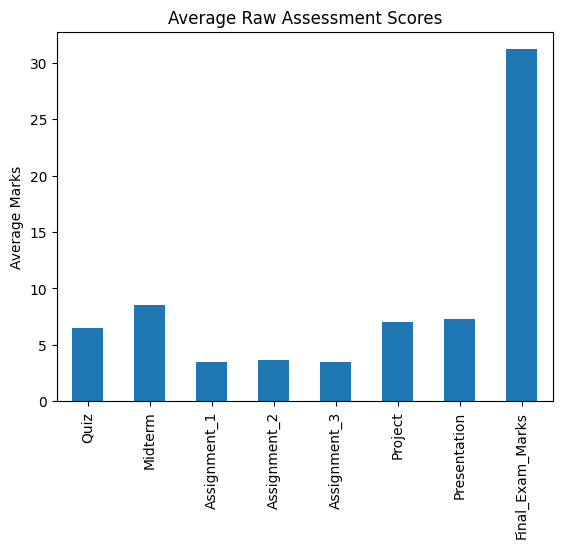

In [51]:
scores = ["Quiz", "Midterm", "Assignment_1",
    "Assignment_2", "Assignment_3",
    "Project", "Presentation",
    "Final_Exam_Marks"]

print(df[scores].mean())

df[scores].mean().plot(kind="bar")
plt.title("Average Raw Assessment Scores")
plt.ylabel("Average Marks")
plt.show()

These are average raw marks. Assessments may have different maximum scores, so their averages cannot be directly compared as percentages of performance.

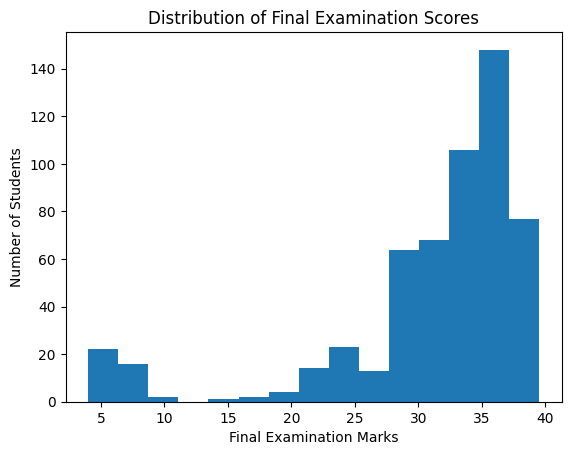

In [52]:
df["Final_Exam_Marks"].plot(kind="hist", bins=15)

plt.title("Distribution of Final Examination Scores")
plt.xlabel("Final Examination Marks")
plt.ylabel("Number of Students")
plt.show()

In [53]:
correlation = df[scores].corr()

print(correlation)

                      Quiz   Midterm  Assignment_1  Assignment_2  \
Quiz              1.000000  0.186181      0.061898     -0.055432   
Midterm           0.186181  1.000000      0.142818      0.199086   
Assignment_1      0.061898  0.142818      1.000000      0.300505   
Assignment_2     -0.055432  0.199086      0.300505      1.000000   
Assignment_3      0.095669  0.097669      0.239214      0.067009   
Project           0.285692  0.266434      0.159982      0.126251   
Presentation      0.475769  0.204355      0.143304      0.138718   
Final_Exam_Marks  0.072828  0.289776      0.089579     -0.064481   

                  Assignment_3   Project  Presentation  Final_Exam_Marks  
Quiz                  0.095669  0.285692      0.475769          0.072828  
Midterm               0.097669  0.266434      0.204355          0.289776  
Assignment_1          0.239214  0.159982      0.143304          0.089579  
Assignment_2          0.067009  0.126251      0.138718         -0.064481  
Assignment_3

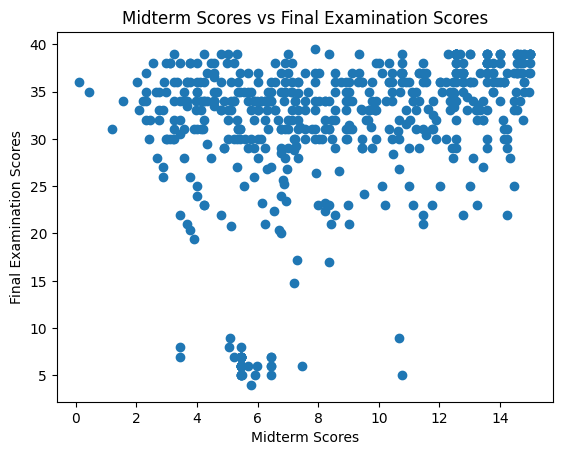

In [54]:
plt.scatter(df["Midterm"], df["Final_Exam_Marks"])

plt.title("Midterm Scores vs Final Examination Scores")
plt.xlabel("Midterm Scores")
plt.ylabel("Final Examination Scores")
plt.show()

In [55]:
print(df.groupby("Categories")[scores].mean())

                 Quiz    Midterm  Assignment_1  Assignment_2  Assignment_3  \
Categories                                                                   
Distinction  6.496279   8.054459      3.482492      3.585781      3.459136   
Excellent    7.244714  11.573967      3.442000      3.903429      3.471857   
Exceptional  8.541786  13.785357      4.261607      4.289125      4.312857   
Fail         6.500732   5.484390      3.151707      4.003171      3.163659   
Pass         4.589022   6.023979      3.245435      3.267391      3.345109   

              Project  Presentation  Final_Exam_Marks  
Categories                                             
Distinction  7.027641      7.213389         33.034551  
Excellent    8.293143      8.359714         36.174286  
Exceptional  8.713750      9.305536         38.125000  
Fail         5.499024      6.514878          7.634146  
Pass         5.760978      5.869783         27.544565  


## 3. Data Preprocessing — Solomon

In [56]:
# Check column names
print("Columns:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check exact duplicate rows
print("\nExact duplicate rows:", df.duplicated().sum())

# Check duplicate student IDs
print("\nDuplicate Student IDs:", df["Student Id"].duplicated().sum())

# Check the outcome categories
print("\nOutcome categories:")
print(df["Categories"].value_counts())

# Check data types
print("\nData types:")
print(df.dtypes)

Columns:
['Student Id', 'Quiz', 'Midterm', 'Assignment_1', 'Assignment_2', 'Assignment_3', 'Project', 'Presentation', 'Final_Exam_Marks', 'Total', 'Grade', 'Categories']

Missing values:
Student Id          0
Quiz                0
Midterm             0
Assignment_1        0
Assignment_2        0
Assignment_3        0
Project             0
Presentation        0
Final_Exam_Marks    0
Total               0
Grade               0
Categories          0
dtype: int64

Exact duplicate rows: 0

Duplicate Student IDs: 0

Outcome categories:
Categories
Distinction    301
Pass            92
Excellent       70
Exceptional     56
Fail            41
Name: count, dtype: int64

Data types:
Student Id            int64
Quiz                float64
Midterm             float64
Assignment_1        float64
Assignment_2        float64
Assignment_3        float64
Project             float64
Presentation        float64
Final_Exam_Marks    float64
Total               float64
Grade                object
Categories 

In [57]:
# Remove exact duplicate rows if any exist
df = df.drop_duplicates()

# Check missing values again
print("Missing values after duplicate removal:")
print(df.isnull().sum())

# Check student ID uniqueness
print("Unique student IDs:", df["Student Id"].nunique())

Missing values after duplicate removal:
Student Id          0
Quiz                0
Midterm             0
Assignment_1        0
Assignment_2        0
Assignment_3        0
Project             0
Presentation        0
Final_Exam_Marks    0
Total               0
Grade               0
Categories          0
dtype: int64
Unique student IDs: 560


In [58]:
# Fail = 1, everyone else = 0
y = (df["Categories"] == "Fail").astype(int)

print("Label distribution:")
print(y.value_counts())

print("\nLabel percentages:")
print(y.value_counts(normalize=True) * 100)

Label distribution:
Categories
0    519
1     41
Name: count, dtype: int64

Label percentages:
Categories
0    92.678571
1     7.321429
Name: proportion, dtype: float64


In [59]:
# Provisional features available before the final exam
feature_list = [
    "Quiz",
    "Midterm",
    "Assignment_1",
    "Assignment_2",
    "Assignment_3",
    "Project",
    "Presentation"
]

X = df[feature_list].copy()

print("Selected features:")
print(X.columns.tolist())

display(X.head())

Selected features:
['Quiz', 'Midterm', 'Assignment_1', 'Assignment_2', 'Assignment_3', 'Project', 'Presentation']


,Quiz,Midterm,Assignment_1,Assignment_2,Assignment_3,Project,Presentation
0,2.34,6.78,4.56,3.24,4.56,5.67,7.89
1,8.17,12.43,2.87,1.87,2.89,2.34,2.34
2,5.92,3.21,0.45,4.56,0.76,8.90,5.67
3,1.45,9.87,3.12,2.34,3.01,1.23,1.23
4,9.78,5.34,0.98,0.98,1.98,9.45,9.01


In [60]:
# Combining the prepared features and pass/fail label
cleaned_data = X.copy()
cleaned_data["Fail"] = y

# Saving the cleaned dataset
cleaned_data.to_csv("cleaned_data.csv", index=False)

print("Cleaned dataset saved.")



Cleaned dataset saved.


In [61]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

X_train: (448, 7)
X_test: (112, 7)
y_train: (448,)
y_test: (112,)

Training label distribution:
Categories
0    415
1     33
Name: count, dtype: int64

Testing label distribution:
Categories
0    104
1      8
Name: count, dtype: int64


In [62]:
print("Features used:")
print(feature_list)

print("\nLabel definition:")
print("Fail = 1, Non-Fail = 0")

print("\nTraining failures:", y_train.sum())
print("Testing failures:", y_test.sum())

print("\nTraining non-failures:", (y_train == 0).sum())
print("Testing non-failures:", (y_test == 0).sum())

Features used:
['Quiz', 'Midterm', 'Assignment_1', 'Assignment_2', 'Assignment_3', 'Project', 'Presentation']

Label definition:
Fail = 1, Non-Fail = 0

Training failures: 33
Testing failures: 8

Training non-failures: 415
Testing non-failures: 104


In [63]:
# Saving the train and test sets
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)

y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

print("Train and test sets saved.")

Train and test sets saved.


## 4. Model Training and Comparison — Eiza

In [64]:
# Importing models and training tools
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [65]:
# Creating a decision tree with limited depth
decision_tree = DecisionTreeClassifier(
    max_depth = 3,
    random_state = 42
)

In [66]:
# Scaling features and applying logistic regression
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [67]:
# Dividing the training data into five stratified folds
cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = 42
)

In [68]:
# Setting the metrics for comparing the models
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

In [69]:
# Evaluating logistic regression using training data only
logistic_scores = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True
)

# Evaluating the decision tree using the same folds
tree_scores = cross_validate(
    decision_tree,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True
)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [70]:
# Displaying average training and validation scores
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Training F1": [
        logistic_scores["train_f1"].mean(),
        tree_scores["train_f1"].mean()
    ],
    "Validation Accuracy": [
        logistic_scores["test_accuracy"].mean(),
        tree_scores["test_accuracy"].mean()
    ],
    "Validation Precision": [
        logistic_scores["test_precision"].mean(),
        tree_scores["test_precision"].mean()
    ],
    "Validation Recall": [
        logistic_scores["test_recall"].mean(),
        tree_scores["test_recall"].mean()
    ],
    "Validation F1": [
        logistic_scores["test_f1"].mean(),
        tree_scores["test_f1"].mean()
    ]
})

comparison.round(3)

,Model,Training F1,Validation Accuracy,Validation Precision,Validation Recall,Validation F1
0,Logistic Regression,0.104,0.929,0.300,0.062,0.100
1,Decision Tree,0.801,0.958,0.823,0.586,0.667


In [71]:
# Selecting the model with the higher average validation F1
if logistic_scores["test_f1"].mean() >= tree_scores["test_f1"].mean():
    best_model = logistic_model
    best_model_name = "Logistic Regression"
else:
    best_model = decision_tree
    best_model_name = "Decision Tree"

# Training the selected model on all training records
best_model.fit(X_train, y_train)

print("Selected model:", best_model_name)

Selected model: Decision Tree


## 5. Model Evaluation — Odinaka

Baseline Accuracy: 0.9285714285714286
Precision score: 0.0
Recall: 0.0
Confusion matrix: [[104   0]
 [  8   0]]
Baseline Accuracy: 0.4017857142857143
Precision score: 0.046153846153846156
Recall: 0.375
Confusion matrix: [[42 62]
 [ 5  3]]


,Actual Outcome,Predicted Outcome,Pass Probability,Fail Probability
0,0,0,1.000000,0.000000
1,0,0,1.000000,0.000000
2,0,0,1.000000,0.000000
3,1,1,0.000000,1.000000
4,0,0,0.953704,0.046296
5,0,0,1.000000,0.000000
6,0,0,0.953704,0.046296
7,0,0,1.000000,0.000000
8,0,0,1.000000,0.000000
9,0,0,1.000000,0.000000


Predicted outcomes:
[0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0
 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0]
Actual outcomes:
249    0
417    0
90     0
319    1
523    0
      ..
363    0
509    1
272    0
46     0
220    0
Name: Categories, Length: 112, dtype: int64
Confusion Matrix:
[[103   1]
 [  3   5]]


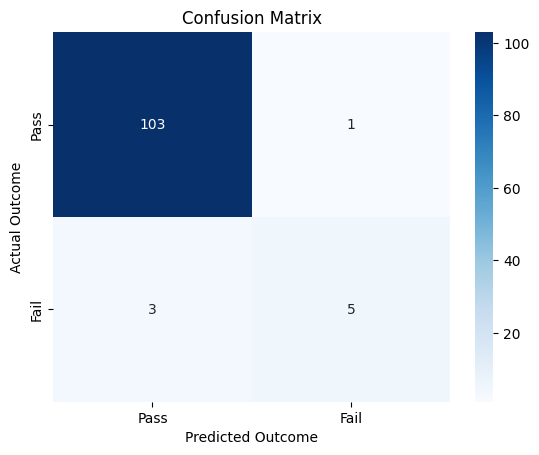

Accuracy: 0.9642857142857143
Failure Precision: 0.8333333333333334
Failure Recall: 0.625
F1 Score: 0.7142857142857143
Total students in test set: 112
Actual failures: 8
Actual passes: 104

MODEL COMPARISON
Baseline Accuracy: 0.9285714285714286
Selected Model Accuracy: 0.9642857142857143

Selected Model Performance
Precision: 0.8333333333333334
Recall: 0.625
F1 Score: 0.7142857142857143

The selected model has higher accuracy than the baseline.


In [72]:
#We will use the following evaluation metrics;
#Measuring overall correctness, while recognising that accuracy can hide poor failure detection when most students pass
#Precision- how many students predicted to fail actually failed.
#Recall tells you how many of the students who actually failed were correctly identified.
#F1 -The F1 score combines precision and recall into one measurement.

#import the model and the metrics
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ( accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_predictions)
baseline_precision = precision_score(
    y_test, baseline_predictions,
    pos_label=1, zero_division=0
)
baseline_recall = recall_score(
    y_test, baseline_predictions,
    pos_label=1, zero_division=0
)
baseline_cm = confusion_matrix(
    y_test, baseline_predictions,
    labels=[0, 1]
)

print("Baseline Accuracy:", baseline_accuracy)
print("Precision score:",baseline_precision)
print("Recall:",baseline_recall)
print("Confusion matrix:", baseline_cm)

baseline_uniform = DummyClassifier(
    strategy="uniform",
    random_state=42
)
baseline_uniform.fit(X_train, y_train)
uniform_predictions = baseline_uniform.predict(X_test)


uniform_accuracy = accuracy_score(y_test, uniform_predictions)
uniform_precision = precision_score(
    y_test, uniform_predictions,
    pos_label=1, zero_division=0
)
uniform_recall = recall_score(
    y_test, uniform_predictions,
    pos_label=1, zero_division=0
)
uniform_cm = confusion_matrix(
    y_test, uniform_predictions,
    labels=[0, 1]
)

print("Baseline Accuracy:", uniform_accuracy)
print("Precision score:",uniform_precision)
print("Recall:",uniform_recall)
print("Confusion matrix:", uniform_cm)


#Predicting the outcomes using the model. Note: replace best_model with actual model used
y_pred = best_model.predict(X_test)

# Calculating estimated probabilities of passing and failing
probabilities = best_model.predict_proba(X_test)

probability_results = pd.DataFrame({
    "Actual Outcome": y_test.to_numpy(),
    "Predicted Outcome": y_pred,
    "Pass Probability": probabilities[:, 0],
    "Fail Probability": probabilities[:, 1]
})

display(probability_results.head(10))

print("Predicted outcomes:")
print(y_pred)

print("Actual outcomes:")
print(y_test)
#Rememebr 0=pass, 1=fail
#confuion matrix
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

# Plot confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pass", "Fail"],
    yticklabels=["Pass", "Fail"]
)

plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.title("Confusion Matrix")
plt.show()


#Scores for the actual model
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

recall = recall_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

print("Accuracy:", accuracy)
print("Failure Precision:", precision)
print("Failure Recall:", recall)
print("F1 Score:", f1)

#Finding the total number of failures to inteprete recall
actual_failures = (y_test == 1).sum()
actual_passes = (y_test == 0).sum()

print("Total students in test set:", len(y_test))
print("Actual failures:", actual_failures)
print("Actual passes:", actual_passes)

#Model comparison with baseline
print("\nMODEL COMPARISON")

print("Baseline Accuracy:", baseline_accuracy)
print("Selected Model Accuracy:", accuracy)

print("\nSelected Model Performance")
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

if accuracy > baseline_accuracy:
    print("\nThe selected model has higher accuracy than the baseline.")
elif accuracy == baseline_accuracy:
    print("\nThe selected model has the same accuracy as the baseline.")
else:
    print("\nThe selected model has lower accuracy than the baseline.")

The Decision Tree was selected because it achieved a higher average cross-validation F1 score than Logistic Regression (0.667 compared with 0.100). On the test set, it achieved 96.43% accuracy, 83.33% failure precision, 62.5% failure recall and an F1 score of 71.43%. It correctly identified five of eight students who failed, while missing three and incorrectly flagging one student who passed. The majority-class baseline achieved 92.86% accuracy but identified no failures.

These results suggest that assessment scores may help identify students at risk of course failure. However, the test set contained only eight failure cases, so the findings remain uncertain. The model's probability outputs are estimates, including values of 0 or 1, and should not be interpreted as guaranteed outcomes. This study uses an external AI course dataset and does not establish performance at PAU. It also does not test the attendance, study habits or CA1/CA2 prediction points originally proposed, because these are not documented in the selected dataset.